# Tarea 2 — Inteligencia Artificial



- Integrantes: Andrés Hormazabal, Héctor Vines.
- Profesor: Johan Fuentes. 
- Ayudantes: Dante Libiot, Miguel Pereira, Matias Vasquez.
- URL del dataset utilizado para la pregunta 1: https://www.kaggle.com/datasets/saichaitanyareddyai/spotify-tracks-dataset-audio-features

- URL del dataset utilizado para la pregunta 2: https://www.kaggle.com/datasets/fedesoriano/stellar-classification-dataset-sdss17


In [5]:
import os
import kagglehub
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import learning_curve
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from pandas.plotting import scatter_matrix


In [6]:
# Codigo para descargar los datasets de manera online

path_sdss_dir = kagglehub.dataset_download("fedesoriano/stellar-classification-dataset-sdss17")
sdss_file = os.path.join(path_sdss_dir, "star_classification.csv")
df_sdss = pd.read_csv(sdss_file)
print("Dataset SDSS17 cargado correctamente.")

# 2. Descargar y cargar 
path_spotify= kagglehub.dataset_download("saichaitanyareddyai/spotify-tracks-dataset-audio-features")
spotify_file = os.path.join(path_spotify, "spotify-tracks-dataset-detailed.csv")
df_spotify = pd.read_csv(spotify_file)
print("Dataset Spotify cargado correctamente.")

Dataset SDSS17 cargado correctamente.
Dataset Spotify cargado correctamente.


In [7]:
#Codigo para importar los datasets desde el proyecto

os.makedirs("data/raw", exist_ok=True)

path_sdss = "data/raw/star_classification.csv"
path_spotify = "data/raw/spotify-tracks-dataset-detailed.csv"


if os.path.exists(path_sdss):
    df_sdss = pd.read_csv(path_sdss)
    print("Dataset SDSS17 cargado correctamente.")
else:
    print(f"Error: Coloca el archivo descargado en la ruta '{path_sdss}'")

if os.path.exists(path_spotify):
    df_spotify = pd.read_csv(path_spotify)
    print("Dataset Spotify cargado correctamente.")
else:
    print("Error")

Dataset SDSS17 cargado correctamente.
Dataset Spotify cargado correctamente.


## Parte 1 — Algoritmos de aprendizaje supervizado

El dataset elegido fue el `spotify-tracks-dataset-detailed.csv` por la cantidad de filas y columnas que tiene, ya que cumple con los requerimientos de la tarea. Además, el área de la música es interesante para nosotros, y poder usar un dataset de este dominio, permitirá ver cómo se ajusta un proceso de Machine Learning para este tipo de datos.


### 1.0 Dataset y variables

| # | Columna | Descripción | Tipo |
|---|---|---|---|
| 0 | track_id | Identificador único de la pista en Spotify | Categórica (texto) |
| 1 | artists | Artista(s) que interpretan la pista, separados por ; | Categórica (texto) |
| 2 | album_name | Nombre del álbum en que aparece la pista | Categórica (texto) |
| 3 | track_name | Nombre de la pista | Categórica (texto) |
| 4 | popularity | Popularidad de la pista (0 a 100), según reproducciones recientes | Numérica discreta |
| 5 | duration_ms | Duración de la pista en milisegundos | Numérica continua |
| 6 | explicit | Indica si la pista tiene contenido explícito | Binaria (booleana) |
| 7 | danceability | Qué tan bailable es la pista (0.0 a 1.0) | Numérica continua |
| 8 | energy | Intensidad y actividad percibida de la pista (0.0 a 1.0) | Numérica continua |
| 9 | key | Tonalidad de la pista (0 = Do, 1 = Do#, ..., 11 = Si) | Categórica (codificada numéricamente) |
| 10 | loudness | Volumen promedio de la pista en decibelios (dB) | Numérica continua |
| 11 | mode | Modalidad de la pista (1 = mayor, 0 = menor) | Binaria |
| 12 | speechiness | Presencia de palabras habladas en la pista (0.0 a 1.0) | Numérica continua |
| 13 | acousticness | Confianza de que la pista sea acústica (0.0 a 1.0) | Numérica continua |
| 14 | instrumentalness | Probabilidad de que la pista no contenga voz (0.0 a 1.0) | Numérica continua |
| 15 | liveness | Probabilidad de que la pista sea una grabación en vivo (0.0 a 1.0) | Numérica continua |
| 16 | valence | Positividad musical transmitida por la pista (0.0 a 1.0) | Numérica continua |
| 17 | tempo | Tempo estimado de la pista en pulsos por minuto (BPM) | Numérica continua |
| 18 | time_signature | Compás estimado de la pista (pulsos por compás) | Numérica discreta |
| 19 | track_genre | Género musical asociado a la pista | Categórica (texto) |





Este es un problema de entrenamiento supervizado, dado que el modelo puede ser entrenado con ejemplos etiquetados.  

> La tarea 1 del modelo consistira en: dadas las características acústicas de una canción, se tiene predice su `popularidad`. Se ocupara `regresión lineal` para realizar esta tarea y el momento de la predicción sera cuando tenga una cantidad no nula de reproducciones.

> La tarea 2 de este modelo será: dadas las mismas características ocupadas en el modelo anterior, se puede predecir si el contenido es `explícito`. Lo que se espera es que las características acústicas de una canción no esten relacionadas a si tiene un contenido explícito o no.


In [ ]:

df_spotify.info()
df_spotify.describe()

#Conteno de nulos por columna 
print("\nConteo de nulos por columna:")
print(df_spotify.isnull().sum()[df_spotify.isnull().sum() > 0])

print("---------")
# Limpieza
print("Duplicados por track_id:", df_spotify['track_id'].duplicated().sum())
print("Filas completamente duplicadas:", df_spotify.duplicated().sum())

print("---------")

df_clean = df_spotify.drop_duplicates(subset='track_id', keep=('first')).copy()
print("Filas:", len(df_clean))
print("Duplicados restantes: ", df_clean['track_id'].duplicated().sum())

print("---------")

for c in ['tempo', 'duration_ms', 'danceability']:
    print(c, "ceros:", (df_clean[c] == 0).sum())


print("---------")
print("Antes:", len(df_clean))

mask_valid = (df_clean['tempo'] != 0) & (df_clean['danceability'] != 0) & (df_clean['duration_ms'] != 0) & (df_clean['popularity'] != 0)

df_clean = df_clean[mask_valid]

print("Después:", len(df_clean))


for c in ['tempo', 'duration_ms', 'danceability', 'popularity']:
    print(c, "ceros:", (df_clean[c] == 0).sum())


print("---------")

print("Proporción explicit:", df_clean['explicit'].mean())


<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  str    
 1   artists           113999 non-null  str    
 2   album_name        113999 non-null  str    
 3   track_name        113999 non-null  str    
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           114000 non-nu

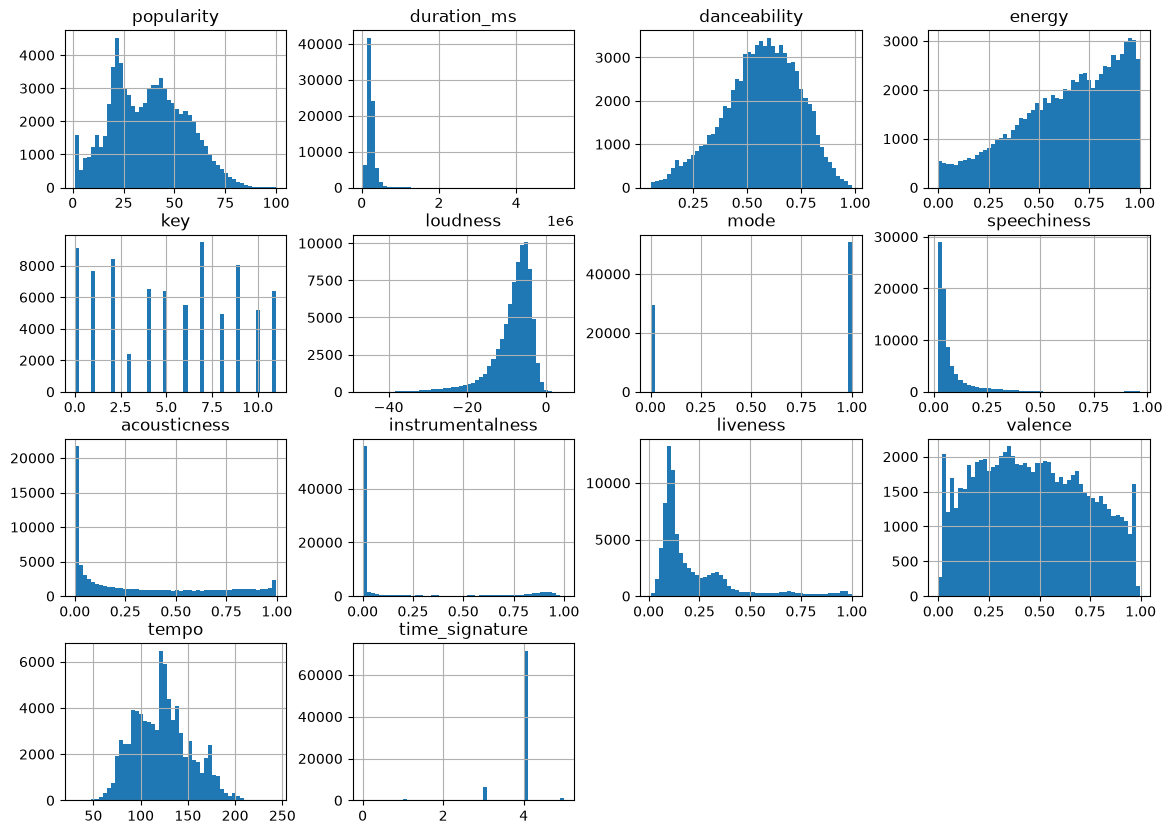

In [45]:

df_clean.hist(bins=50, figsize=(14,10))
plt.show()

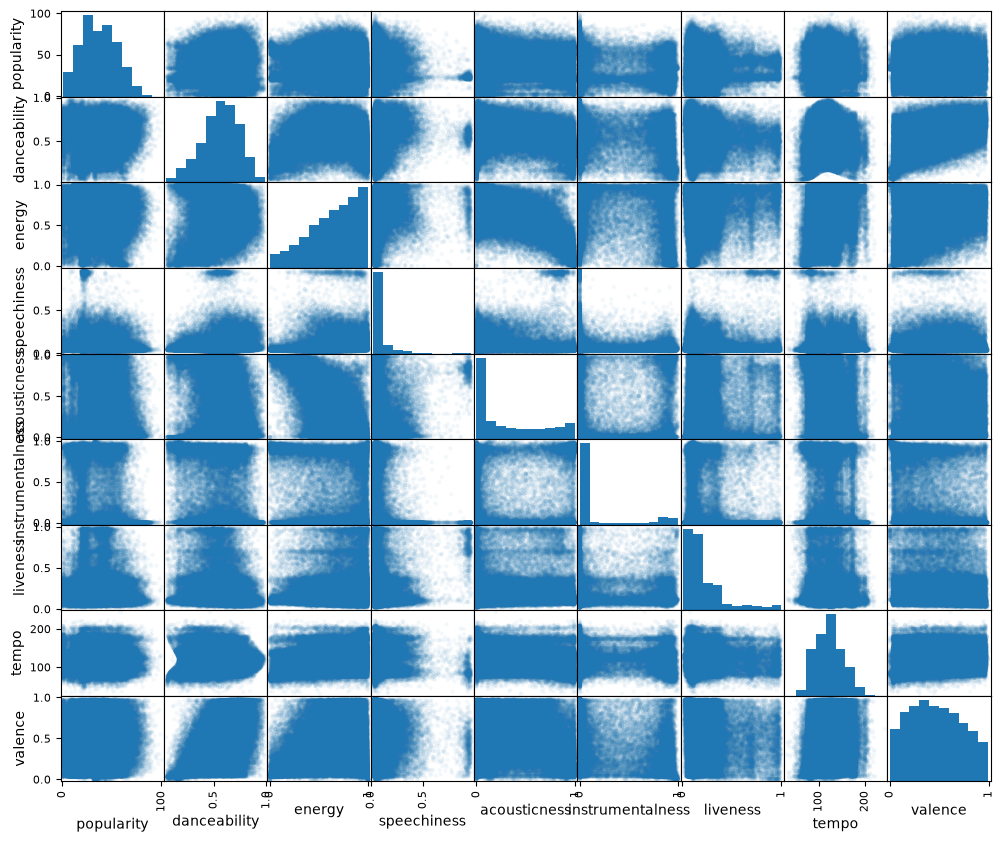

In [72]:

# Eleccion de variables predictorias
attributes = [
    'popularity',
    'danceability',
    'energy',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'tempo',
    'valence'
]
scatter_matrix(df_clean[attributes], figsize=(12, 10), alpha=0.05)
plt.show() 

### 1.1 Selección de variables objetivo (Y1, Y2) y predictoras (X1,...,X10)

> La variable continua $Y_1$ elegida es `popularity`.

> La variable discreta binaria $Y_2$ elegida es `explicit`.

> Las 10 variables predictoras iniciales elegidas son : `duration_ms`,`danceability`,`energy`,`loudness`,`speechiness`,`acousticness`,`instrumentalness`,`liveness`,`tempo`,`valence`.

### 1.2 División del dataset (70% entrenamiento / 15% validación / 15% prueba)

In [ ]:
seed = 42
split_test = 0.15
split_val = 0.15

print(df_clean['explicit'].mean())

split_relative_val = split_val / (1 - split_test)
print(f"Proporción para el paso 2: {split_relative_val}")

# 1. Apartar set de pruebas
temp, df_test  = train_test_split(df_clean, test_size=split_test, random_state=seed)

# 2. partir el resto 
df_train, df_val = train_test_split(temp, test_size=split_relative_val, random_state=seed)

n = len(df_clean)
for nombre, conj in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"{nombre:}: {len(conj):} filas  ({len(conj)/n})")
print(f"{'TOTAL': }: {len(df_train) + len(df_val) + len(df_test):} filas")


0.08651110556526079
Proporción para el paso 2: 0.17647058823529413
train: 56098 filas  (0.7)
val: 12021 filas  (0.15)
test: 12021 filas  (0.15)
TOTAL :  80140 filas


In [68]:
for nombre, conj in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"{nombre}: {conj['explicit'].mean()}")

print(df_train[['energy','loudness']].corr())


train: 0.08704410139398909
val: 0.08551701189584893
test: 0.08501788536727393
            energy  loudness
energy    1.000000  0.756754
loudness  0.756754  1.000000


In [76]:

# variables predictorias
candidates = [ 
    'duration_ms',
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'tempo',
    'valence',
]

#df_train['explicit'] = int(df_train['explicit']) 

print(df_train[candidates + ['popularity']].corr()['popularity'].abs().sort_values(ascending=False))


popularity          1.000000
instrumentalness    0.193335
speechiness         0.087724
danceability        0.076011
loudness            0.075518
duration_ms         0.062281
liveness            0.051351
energy              0.034354
tempo               0.018312
acousticness        0.004791
valence             0.002733
Name: popularity, dtype: float64


## Pregunta 1.A — Regresión lineal (Y1 continua)

### 1.A.1 Selección de variables (solo con datos de entrenamiento)

_Justificar el criterio (correlación, información mutua, coeficientes, etc.) y obtener el ranking; definir los subconjuntos de 10, 5 y 3 variables._

### 1.A.2 Entrenamiento de las tres versiones (10, 5 y 3 variables)

### 1.A.3 Comparación en entrenamiento y validación

_Métricas apropiadas: RMSE, MAE, R²._

$\mathrm{RMSE}(\mathbf{X},h)=\sqrt{\frac{1}{m}\sum_{i=1}^{m}\bigl(h(\mathbf{x}^{(i)})-y^{(i)}\bigr)^{2}}$

$\mathrm{MSE}(\mathbf{X},h_{\boldsymbol{\theta}})=\frac{1}{m}\sum_{i=1}^{m}\bigl(\boldsymbol{\theta}^{\!\top}\mathbf{x}^{(i)}-y^{(i)}\bigr)^{2}$

### 1.A.4 Evaluación en prueba de las dos mejores versiones (según validación)

## Pregunta 1.B — Regresión logística (Y2 binaria)

### 1.B.1 Selección de variables (solo con datos de entrenamiento)

### 1.B.2 Entrenamiento de las tres versiones (10, 5 y 3 variables)

### 1.B.3 Comparación en entrenamiento y validación

_Métricas apropiadas: accuracy, precision, recall, F1, ROC-AUC, matriz de confusión._

### 1.B.4 Evaluación en prueba de las dos mejores versiones (según validación)

## 1.C — Análisis final de la Pregunta 1

_Influencia de la cantidad de variables predictoras en el desempeño y la generalización; discusión de overfitting / underfitting (curvas de aprendizaje, brecha train vs. validación)._

---
# Parte 2 — Aprendizaje supervisado vs. semisupervisado

### 2.0 Dataset y variables

_Descripción del dataset SDSS17 (≥15.000 filas, ≥7 características, etiqueta multiclase `class`: GALAXY, STAR, QSO). Justificar variables utilizadas._

In [15]:
# Carga y exploración inicial de df_sdss

### 2.1 Preprocesamiento

_Selección de características, limpieza, escalamiento, codificación de la etiqueta._

### 2.2 División de datos (80% entrenamiento / 20% testing) y escenarios de etiquetas

_Escenario A: 10% del entrenamiento con etiquetas. Escenario B: 30% del entrenamiento con etiquetas. Fijar semillas._

## 2.A — Baseline supervisado (solo muestras etiquetadas)

### 2.A.1 Regresión Logística — hiperparámetros y justificación (≥3 configuraciones)

_Selección por validación cruzada, sin usar etiquetas desconocidas ni testing. Función de pérdida y métricas._

### 2.A.2 SVM — hiperparámetros y justificación (≥3 configuraciones)

## 2.B — Clustering para pseudoetiquetado

### 2.B.1 K-Means (≥2 configuraciones)

### 2.B.2 DBSCAN (≥2 configuraciones)

### 2.B.3 Estrategia de asignación de pseudoetiquetas

_Criterios de asignación, objetivo de llegar al 60% del conjunto de entrenamiento (reales + estimadas), calidad de las pseudoetiquetas y limitaciones que impidan alcanzar el porcentaje._

## 2.C — Entrenamiento con pseudoetiquetas (semisupervisado)

### 2.C.1 Regresión Logística + pseudoetiquetas (K-Means / DBSCAN)

_≥3 configuraciones de hiperparámetros, selección por validación cruzada._

### 2.C.2 SVM + pseudoetiquetas (K-Means / DBSCAN)

_≥3 configuraciones de hiperparámetros, selección por validación cruzada._

### 2.C.3 Registro de todas las configuraciones evaluadas

_Tabla con configuraciones, funciones de pérdida y métricas._

## 2.D — Comparación final de los seis mejores enfoques

_2 supervisados + 4 semisupervisados, en ambos escenarios (10% y 30%), con al menos 3 semillas aleatorias (media ± desviación estándar)._

## 2.E — Análisis y conclusiones de la Pregunta 2

_Influencia de los hiperparámetros, la cantidad de etiquetas reales y la calidad de las pseudoetiquetas._

---
## Declaración de uso de herramientas generativas

_Declarar específicamente el propósito para el que fueron empleadas (no se permite su uso para diseño de soluciones ni análisis de resultados)._